In [15]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from PIL import Image
import random

from torchvision import transforms
import torchvision.models as models
from sklearn.model_selection import train_test_split

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F

import cv2
from torch.utils.data import Dataset, DataLoader
from sklearn.preprocessing import LabelEncoder
from tqdm.auto import tqdm
from sklearn.metrics import roc_auc_score

## Подготовка данных

In [2]:
train_df = pd.read_csv("ML9_dataset/Train.csv")
test_df = pd.read_csv("ML9_dataset/Test.csv")
sample = pd.read_csv("ML9_dataset/SampleSubmission.csv")

In [3]:
ran_rows = random.sample(range(0, train_df.shape[0]), 10)

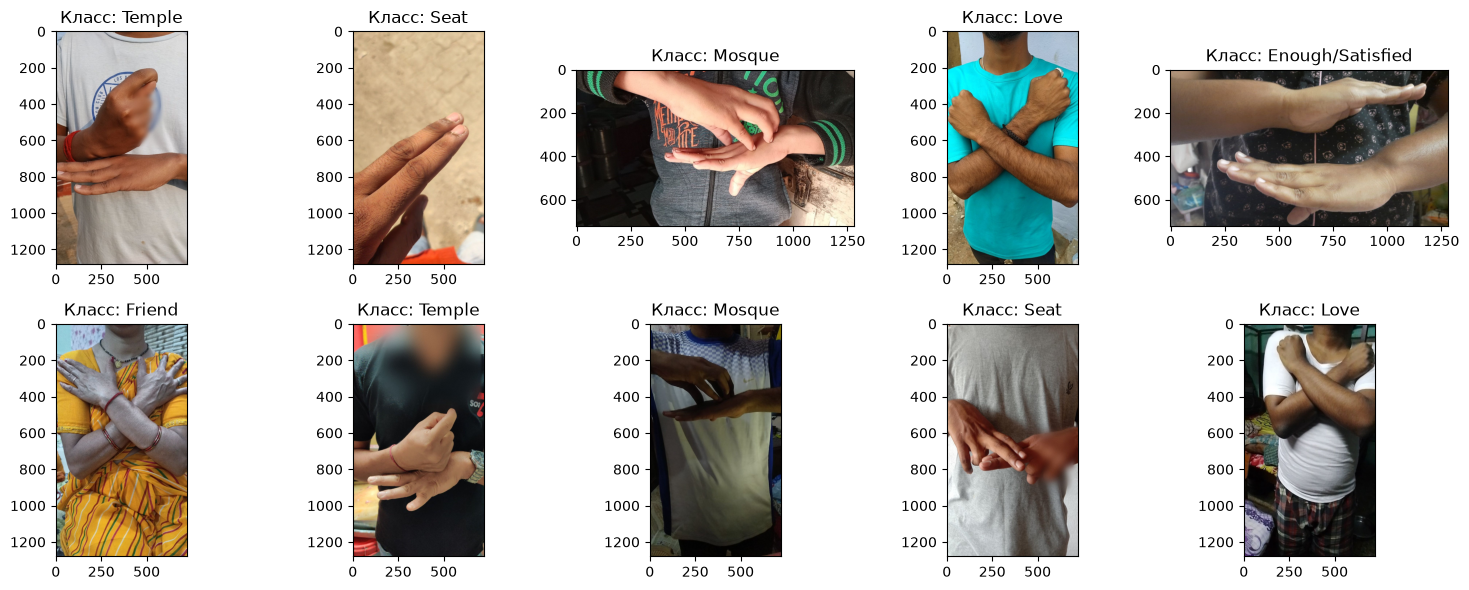

In [4]:
fig, ax = plt.subplots(2, 5, figsize=(15, 6))
ax = ax.flatten()   
sizze = list()
for i, (ind, row) in enumerate(train_df.iloc[ran_rows].iterrows()):
    img_name = row['img_IDS']
    target = row['Label']
    
    img_path = os.path.join('ML9_dataset/Images/', img_name + '.jpg')

    if os.path.exists(img_path):
        img = Image.open(img_path)
        sizze.append(img.size)
        ax[i].imshow(img)
        ax[i].set_title(f"Класс: {target}")

plt.tight_layout()
plt.show()

In [5]:
sizze

[(720, 1280),
 (720, 1280),
 (1280, 720),
 (720, 1280),
 (1280, 720),
 (720, 1280),
 (720, 1280),
 (720, 1280),
 (720, 1280),
 (720, 1280)]

Тут я заметила, что изображения слишком большие, поэтому ниже применила Resize.

In [6]:
train_transform = transforms.Compose([
    transforms.Resize(32), # маленькая сторона 32
    transforms.RandomCrop(size=32), # обрезка размера 32
    transforms.RandomRotation(degrees=(-10, 10)), # поворот
    transforms.ColorJitter(brightness=0.2, contrast=0.2), # ±20% яркость и контраст
    transforms.RandomPerspective(distortion_scale=0.1, p=0.1, fill=(0,0,0)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

val_transform = transforms.Compose([
    transforms.Resize(32),
    transforms.RandomCrop(size=32),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

Это аугментации, те расширение данных за счет самих данных, но без использования лишней памяти.
\
Я использовала:
- обрезку, чтобы жест не всегда был в центре
- поворот, по горизонтали, но не сильный (от -10 до 10 градусов), чтобы не менялась суть жестов
- изменение свойств, таких как яркость и контростность
- перспеутива, чтобы жесты были под углом в 10% случаев

Все остальные преобразования нужны для дальнейшей корректной обработки данных.

In [7]:
train_data, val_data = train_test_split(train_df, test_size=0.33, stratify=train_df['Label']) # stratify - сохранение пропорций каждого класса    

In [8]:
# !find ML9_dataset/Images -name '*:Zone.Identifier' -delete

Я удалила все файлы, которые указывали на то, что файл скачан из интернета

### Создание своего датасета

In [9]:
class MyImageDataset(Dataset):
    def __init__(self, labels_df, img_dir, transform=None):
        self.img_labels = labels_df
        self.img_dir = img_dir
        self.transform = transform
 
    def __len__(self):
        return len(self.img_labels)
 
    def __getitem__(self, idx):
        img_path = os.path.join(self.img_dir, self.img_labels.iloc[idx, 0] + '.jpg')
        image = cv2.imread(img_path)
        if image is None:
            raise FileNotFoundError(f"Не найдено: {img_path}")

        img = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        img = Image.fromarray(img) # из numpy в PIL
        
        if self.transform:
            img = self.transform(img)

        target = int(self.img_labels.iloc[idx]['Label'])
        target = torch.tensor(target, dtype=torch.long)
        return img, target

In [10]:
le = LabelEncoder()
train_data['Label'] = le.fit_transform(train_data['Label'])
val_data['Label'] = le.transform(val_data['Label'])

In [11]:
# le.classes_
class_to_idx = {cls: i for i, cls in enumerate(le.classes_)}
print(class_to_idx)
print(len(class_to_idx))

{'Church': 0, 'Enough/Satisfied': 1, 'Friend': 2, 'Love': 3, 'Me': 4, 'Mosque': 5, 'Seat': 6, 'Temple': 7, 'You': 8}
9


In [12]:
train_dataset = MyImageDataset(train_data, img_dir='ML9_dataset/Images/', transform=train_transform)
val_dataset = MyImageDataset(val_data, img_dir='ML9_dataset/Images/', transform=val_transform)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)

In [13]:
images, labels = next(iter(train_loader))

print("Информация о DataLoader")
print("Тип images:", type(images))
print("Тип labels:", type(labels))
print("Форма images:", images.shape)
print("Форма labels:", labels.shape)
print("dtype images:", images.dtype)
print("dtype labels:", labels.dtype)
print("Первые 10 меток:", labels[:10])

Информация о DataLoader
Тип images: <class 'torch.Tensor'>
Тип labels: <class 'torch.Tensor'>
Форма images: torch.Size([32, 3, 32, 32])
Форма labels: torch.Size([32])
dtype images: torch.float32
dtype labels: torch.int64
Первые 10 меток: tensor([4, 4, 2, 8, 2, 7, 3, 2, 5, 2])


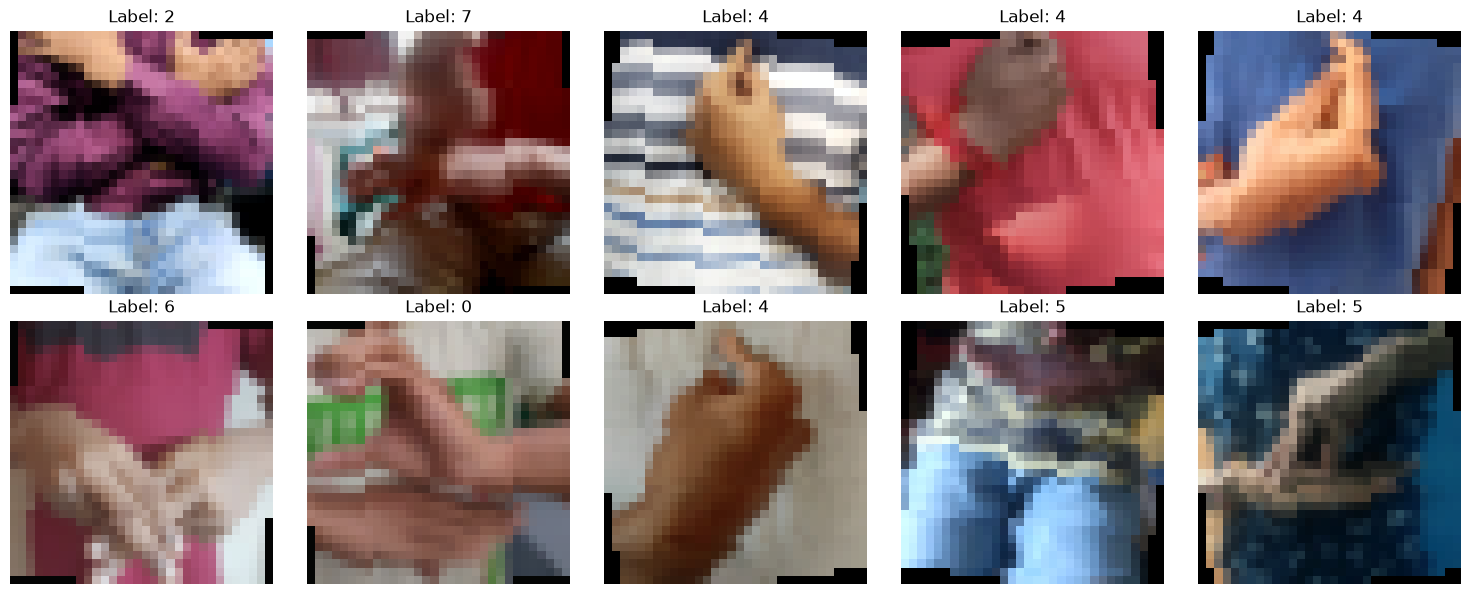

In [14]:
import matplotlib.pyplot as plt
import torch

# Берём один батч
images, labels = next(iter(train_loader))

fig, axes = plt.subplots(2, 5, figsize=(15, 6))
axes = axes.flatten()

for i in range(10):
    img = images[i].permute(1, 2, 0).numpy()

    # приводим к виду, чтобы нрафики смогли отобразиться
    mean = [0.485, 0.456, 0.406]
    std  = [0.229, 0.224, 0.225]
    img = img * std + mean
    img = img.clip(0, 1)  
    
    axes[i].imshow(img)
    axes[i].set_title(f"Label: {labels[i].item()}")
    axes[i].axis('off')

plt.tight_layout()
plt.show()

### Функции

In [36]:
def train_network(model, train_loader, val_loader, loss_model, optimizer, device, epoch, epochs):
    for epoch in range(epochs):
        model.train()
        train_loop = tqdm(train_loader, leave=False)
        for batch_idx, (data, target) in enumerate(train_loop):
            data, target = data.to(device), target.to(device)
            optimizer.zero_grad()
            output = model(data)
            loss = loss_model(output, target)
            loss.backward()
            optimizer.step()
            if batch_idx % 50 == 0:
                train_loop.set_description(f"Epoch[{epoch+1}/{epochs}]    Ошибка: {loss.item()}")
        print(f"Ошибка: {loss.item()}")
    
        model.eval()
        test_loss = 0
        correct = 0
        all_probs = []
        all_targets = []
        
        with torch.no_grad():
            for data, target in val_loader:
                data, target = data.to(device), target.to(device)
                output = model(data)
                test_loss += loss_model(output, target).item() * data.size(0)
                pred = output.argmax(dim=1, keepdim=True)
                correct += pred.eq(target.view_as(pred)).sum().item()
    
                
                probs = torch.softmax(output, dim=1)
                all_probs.append(probs.cpu().numpy())
                all_targets.append(target.cpu().numpy())
    
        test_loss /= len(val_loader.dataset)
    
        all_probs = np.concatenate(all_probs)
        all_targets = np.concatenate(all_targets)
    
        roc_auc = roc_auc_score(
            all_targets,
            all_probs,
            multi_class='ovr',
            average='macro'
        )
        
        print('Val set (Epoch: {}): Average loss: {:.4f}, Accuracy: {}/{} ({:.0f}%), ROC AUC: {:.4f}'.format(
            epoch+1, test_loss, correct, len(val_loader.dataset),
            100. * correct / len(val_loader.dataset), roc_auc))

### Сверточная нейронная сеть (CNN) LeNet-5

In [15]:
class LeNet5(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        self.conv = nn.Sequential(
            # (N, 3, 32, 32)
            nn.Conv2d(3, 32, (3, 3), padding='same', bias=False),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2), # (N, 32, 32, 32) -> (N, 32, 16, 16)
            nn.Dropout2d(0.2),

            nn.Conv2d(32, 64, 3, padding='same', bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2), # (N, 64, 16, 16) -> (N, 64, 8, 8)
            nn.Dropout2d(0.1),
        )

        self.flatten = nn.Flatten()
        self.act = nn.ReLU(inplace=True)

        self.layer_1 = nn.Linear(64 * 8 * 8, 32)
        self.layer_2 = nn.Linear(32, num_classes)

    def forward(self, x):
        x = self.conv(x)
        x = self.flatten(x)
        x = self.layer_1(x)
        x = self.act(x)
        x = self.layer_2(x)
        return x

In [16]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'

In [45]:
model = LeNet5(9).to(device)

loss_model = nn.CrossEntropyLoss()
optimizer = optim.Adam(params=model.parameters(), lr=0.0001) # , weight_decay=0.01

epochs = 20

In [46]:
for epoch in range(epochs):
    model.train()
    train_loop = tqdm(train_loader, leave=False)
    for batch_idx, (data, target) in enumerate(train_loop):
        data, target = data.to(device), target.to(device)
        optimizer.zero_grad()
        output = model(data)
        loss = loss_model(output, target)
        loss.backward()
        optimizer.step()
        if batch_idx % 50 == 0:
            train_loop.set_description(f"Epoch[{epoch+1}/{epochs}]    Ошибка: {loss.item()}")
    print(f"Ошибка: {loss.item()}")

    model.eval()
    test_loss = 0
    correct = 0
    all_probs = []
    all_targets = []
    
    with torch.no_grad():
        for data, target in val_loader:
            data, target = data.to(device), target.to(device)
            output = model(data)
            test_loss += loss_model(output, target).item() * data.size(0)
            pred = output.argmax(dim=1, keepdim=True)
            correct += pred.eq(target.view_as(pred)).sum().item()

            
            probs = torch.softmax(output, dim=1)
            all_probs.append(probs.cpu().numpy())
            all_targets.append(target.cpu().numpy())

    test_loss /= len(val_loader.dataset)

    all_probs = np.concatenate(all_probs)
    all_targets = np.concatenate(all_targets)

    roc_auc = roc_auc_score(
        all_targets,
        all_probs,
        multi_class='ovr',
        average='macro'
    )
    
    print('Test set: Average loss: {:.4f}, Accuracy: {}/{} ({:.0f}%), ROC AUC: {:.4f}'.format(
        test_loss, correct, len(val_loader.dataset),
        100. * correct / len(val_loader.dataset), roc_auc))

  0%|          | 0/131 [00:00<?, ?it/s]

Ошибка: 2.227288007736206
Test set: Average loss: 2.1896, Accuracy: 278/2063 (13%), ROC AUC: 0.5607


  0%|          | 0/131 [00:00<?, ?it/s]

Ошибка: 2.2209413051605225
Test set: Average loss: 2.1763, Accuracy: 327/2063 (16%), ROC AUC: 0.5957


  0%|          | 0/131 [00:00<?, ?it/s]

Ошибка: 2.2118680477142334
Test set: Average loss: 2.1670, Accuracy: 365/2063 (18%), ROC AUC: 0.6180


... (30 outputs left out)

  0%|          | 0/131 [00:00<?, ?it/s]

Ошибка: 2.0133378505706787
Test set: Average loss: 1.7568, Accuracy: 745/2063 (36%), ROC AUC: 0.7983


  0%|          | 0/131 [00:00<?, ?it/s]

Ошибка: 1.786789059638977
Test set: Average loss: 1.7398, Accuracy: 771/2063 (37%), ROC AUC: 0.8023


На 11 эпохе был достигнут минимальный по заданию ROC AUC: 0.7577, а по истечению 20 эпох ROC AUC возрос до 0.8023\
\
Также видно, что после 12 эпохи метрика начала гораздо медленнее увеличиваться, скорее всего для её быстрого роста после ~0,77 нужно менять параметры.

In [ ]:
# model.train()
# for epoch in range(epochs):
#     1. Тренировка модели
#     train_loop = tqdm(train_loader, leave=False)
#     train_loss = 0.0
#     train_correct = 0
#     train_total = 0

#     for x, target in train_loop:
#         x = x.to(device)
#         target = target.to(device)

#         # - Прямой проход + расчёт ошибки модели
#         pred = model(x)
#         loss = loss_model(pred, target)

#         # - Обратный проход
#         optimizer.zero_grad()
#         loss.backward()
#         # - Шаг оптимизации
#         optimizer.step()

#         train_loss += loss.item() * x.size(0)
#         train_correct += (pred.argmax(1) == target).sum().item()
#         train_total += x.size(0)

#         train_loop.set_description(f"Epoch[{epoch+1}/{epochs}]")

#     avg_train_loss = train_loss / train_total
#     train_acc = train_correct / train_total
    
#     val_loss = 0.0
#     val_correct = 0
#     val_total = 0
#     4. Проверка модели (валидация)
#     model.eval()
#     with torch.no_grad():  # запрещаем вычисление градиента внутри with
#         for x, targets in val_loader:
#             x = x.to(device)
#             targets = targets.to(device)

#             # - Прямой проход + расчёт ошибки модели
#             pred = model(x)
#             loss = loss_model(pred, targets)

#             val_loss += loss.item() * x.size(0)
#             val_correct += (pred.argmax(1) == targets).sum().item()
#             val_total += x.size(0)`

#     avg_val_loss = val_loss / val_total
#     val_acc = val_correct / val_total

#     print(f"Epoch {epoch+1}/{epochs} | "
#           f"train_loss={avg_train_loss:.4f} train_acc={train_acc:.4f} | "
#           f"val_loss={avg_val_loss:.4f} val_acc={val_acc:.4f}")            

### Подготовка данных под  ResNet18 

In [37]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

model = models.resnet18(weights='IMAGENET1K_V1')

# Меняем последний слой под свои данные
model.fc = nn.Linear(model.fc.in_features, 9)
model = model.to(device)

Без weights='IMAGENET1K_V1' модель за 5 4 эпохи достигала окло 0,72, этого недостаточно, поэтому добавила параметр с предобученными весами.

In [38]:
loss_model = nn.CrossEntropyLoss()
optimizer = optim.Adam(params=model.parameters(), lr=0.0001)

epochs = 5

In [ ]:
train_network(model, train_loader, val_loader, loss_model, optimizer, device, epoch, epochs)

  0%|          | 0/131 [00:00<?, ?it/s]

Ошибка: 1.4209123849868774
Val set (Epoch: 1): Average loss: 1.6380, Accuracy: 843/2063 (41%), ROC AUC: 0.8176


  0%|          | 0/131 [00:00<?, ?it/s]

Ошибка: 1.1845797300338745
Val set (Epoch: 2): Average loss: 1.4360, Accuracy: 996/2063 (48%), ROC AUC: 0.8662


  0%|          | 0/131 [00:00<?, ?it/s]

Ошибка: 1.180349588394165
Val set (Epoch: 3): Average loss: 1.2813, Accuracy: 1117/2063 (54%), ROC AUC: 0.8939


  0%|          | 0/131 [00:00<?, ?it/s]

Ошибка: 0.9909782409667969


Заданного результата ROC AUC > 0.9 было достигнуто за 4 эпохи

In [ ]:
!git add ml9.ipynb
!git commit -m "Внедрение resnet18"
!git push origin develop

!git add ML9_dataset/Images/
!git commit -m "Данные"
!git push origin develop